# Result analysis

In [107]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import load_case, compute_errors, print_err_mean_std, err_kde_plot, time_kde_plot, err_pointwise_plot, print_exec_times

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

In [108]:
RESULT_DIR = "./results/2025-10-02_11_10"

results = load_case(RESULT_DIR)
# case_cylinder_big = load_case(RESULT_DIR, "cylinder_big")

In [103]:
print(len(results["u_numeric"]))

10




In [109]:
n_cases = len(results["u_numeric"])

fig, ax = plt.subplots(figsize=(20, 120), nrows=n_cases, ncols=3)

for i in range(n_cases):
    Un = np.array(results["u_numeric"][i][:, :, 0], dtype=float)
    Vn = np.array(results["u_numeric"][i][:, :, 1], dtype=float)

    Up = np.array(results["u_poisson"][i][:, :, 0], dtype=float)
    Vp = np.array(results["u_poisson"][i][:, :, 1], dtype=float)

    Uf = np.array(results["u_full"][i][:, :, 0], dtype=float)
    Vf = np.array(results["u_full"][i][:, :, 1], dtype=float)

    height, width = np.shape(results["u_numeric"][i])[0], np.shape(results["u_numeric"][i])[1]
    X, Y = np.meshgrid(np.linspace(0, width, width) + 0.5, 
                       np.linspace(0, height, height) + 0.5)
    

    mag_max = max(
        np.sqrt(Un**2 + Vn**2).max(),
        np.sqrt(Up**2 + Vp**2).max(),
        np.sqrt(Uf**2 + Vf**2).max()
    )

    scale_val = mag_max * 0.3

    ax[i, 0].quiver(X, Y, Un, Vn, color="red", alpha = 1, scale=scale_val, scale_units='xy')
    ax[i, 0].set_aspect('equal', adjustable='box')
    ax[i, 0].set_title("Numeric")

    ax[i, 1].quiver(X, Y, Up, Vp, color="black", alpha = 1, scale=scale_val, scale_units='xy')
    ax[i, 1].quiver(X, Y, Un, Vn, color="red", alpha = 0.8, scale=scale_val, scale_units='xy')
    ax[i, 1].set_aspect('equal', adjustable='box')
    ax[i, 1].set_title("Poisson")

    ax[i, 2].quiver(X, Y, Uf, Vf, color="black", alpha = 1, scale=scale_val, scale_units='xy')
    ax[i, 2].quiver(X, Y, Un, Vn, color="red", alpha = 0.8, scale=scale_val, scale_units='xy')
    ax[i, 2].set_aspect('equal', adjustable='box')
    ax[i, 2].set_title("Full")

plt.tight_layout()

## Errors computation

In [110]:
# err_cylinder_small = compute_errors(case_cylinder_small)
# err_cylinder_tiny = compute_errors(case_cylinder_tiny)
# err_cylinder_medium = compute_errors(case_cylinder_medium)
# # err_cylinder_big = compute_errors(case_cylinder_big)
errors = compute_errors(results)

## Analysis / Visualizations

## Errors

In [111]:
print_err_mean_std(errors)

numeric divergence = 0.2399051664441512 +- 1.8568577309707126

u poisson error = 0.26102487579720546 +- 0.057861587382801505
p poisson error = 0.3229326138513548 +- 0.12972874337806156
poisson divergence error = 1.8778704609095345 +- 4.695420973617071

u full error = 0.5398733209756754 +- 0.08293781131168697
p full error = 0.9888591466756618 +- 0.002634631814484102
full divergence error = 2.8503012494018267 +- 8.456919172115803


### RMSE distributions

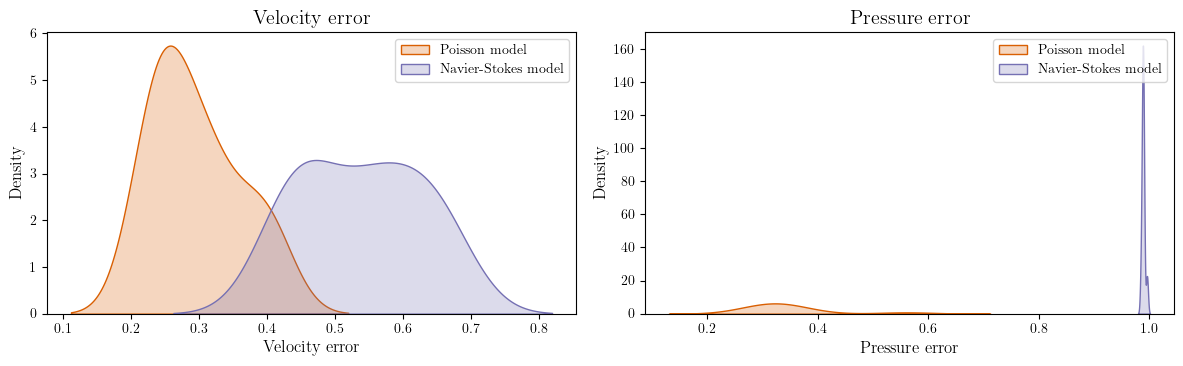

In [69]:
err_kde_plot(errors, title="")

### Pointwise errors

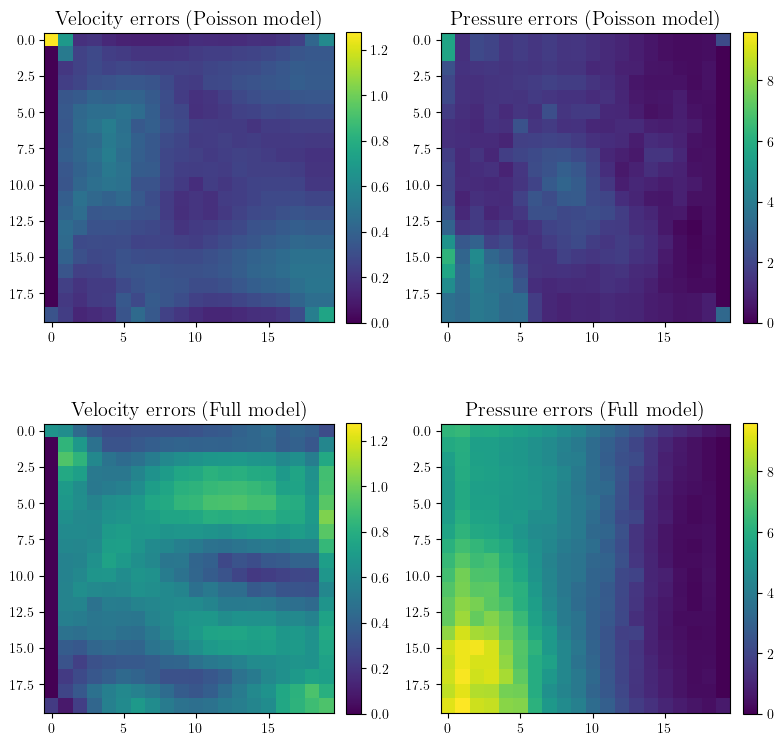

In [70]:
err_pointwise_plot(errors)